In [1]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"   # must come before torch is imported

!pip install -q omegaconf
!test -d /kaggle/working/nejm-brain-to-text || git clone -q https://github.com/Neuroprosthetics-Lab/nejm-brain-to-text /kaggle/working/nejm-brain-to-text

import sys, time, shutil
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from omegaconf import OmegaConf

os.chdir("/kaggle/working/nejm-brain-to-text/model_training")   # the training code expects to run from here
sys.path.append(os.getcwd())
from rnn_trainer import BrainToTextDecoder_Trainer

SESSIONS_DIR = "/kaggle/input/competitions/brain-to-text-25/t15_copyTask_neuralData/hdf5_data_final"
print(torch.__version__, torch.cuda.get_device_name(0))

2.11.0+cu128 Tesla T4


setup

In [2]:
QUICK_TEST = False        # True = 600-batch speed test. Set False for the real run.
N_BATCHES = 600 if QUICK_TEST else 12000   # replace 20000 with the number Cell 5 gives you

RUN_NAME = "rnn_quicktest" if QUICK_TEST else f"rnn_{N_BATCHES}"

    
args = OmegaConf.load("rnn_args.yaml")                 # the official settings
args.dataset.dataset_dir = SESSIONS_DIR                # point at Kaggle's copy of the data
args.dataset.batch_size = 32 
args.output_dir = f"/kaggle/working/runs/{RUN_NAME}"
args.checkpoint_dir = f"{args.output_dir}/checkpoint"
args.gpu_number = "0"
args.use_amp = False                                   # T4s don't support bfloat16 well; use float32
args.num_training_batches = N_BATCHES
args.lr_decay_steps = args.lr_decay_steps_day = N_BATCHES            # shrink the schedule to fit the budget
args.lr_warmup_steps = args.lr_warmup_steps_day = min(1000, N_BATCHES // 10)
args.batches_per_val_step = 300 if QUICK_TEST else N_BATCHES // 10   # ~10 validation checks
args.batches_per_train_log = 100

shutil.rmtree(args.output_dir, ignore_errors=True)    # the trainer refuses to overwrite an existing folder
print(OmegaConf.to_yaml({k: args[k] for k in ["num_training_batches", "lr_decay_steps", "batches_per_val_step", "use_amp", "output_dir"]}))

num_training_batches: 12000
lr_decay_steps: 12000
batches_per_val_step: 1200
use_amp: false
output_dir: /kaggle/working/runs/rnn_12000



training settings

In [3]:
t0 = time.time()
trainer = BrainToTextDecoder_Trainer(args)
stats = trainer.train()
elapsed = time.time() - t0
print(f"\nWall time: {elapsed / 60:.1f} min for {N_BATCHES} batches")

2026-10-10 21:10:58,155: Using device: cuda:0
2026-10-10 21:10:59,269: Using torch.compile
2026-10-10 21:11:02,877: Initialized RNN decoding model
2026-10-10 21:11:02,878: OptimizedModule(
  (_orig_mod): GRUDecoder(
    (day_layer_activation): Softsign()
    (day_weights): ParameterList(
        (0): Parameter containing: [torch.float32 of size 512x512]
        (1): Parameter containing: [torch.float32 of size 512x512]
        (2): Parameter containing: [torch.float32 of size 512x512]
        (3): Parameter containing: [torch.float32 of size 512x512]
        (4): Parameter containing: [torch.float32 of size 512x512]
        (5): Parameter containing: [torch.float32 of size 512x512]
        (6): Parameter containing: [torch.float32 of size 512x512]
        (7): Parameter containing: [torch.float32 of size 512x512]
        (8): Parameter containing: [torch.float32 of size 512x512]
        (9): Parameter containing: [torch.float32 of size 512x512]
        (10): Parameter containing: [torc

train

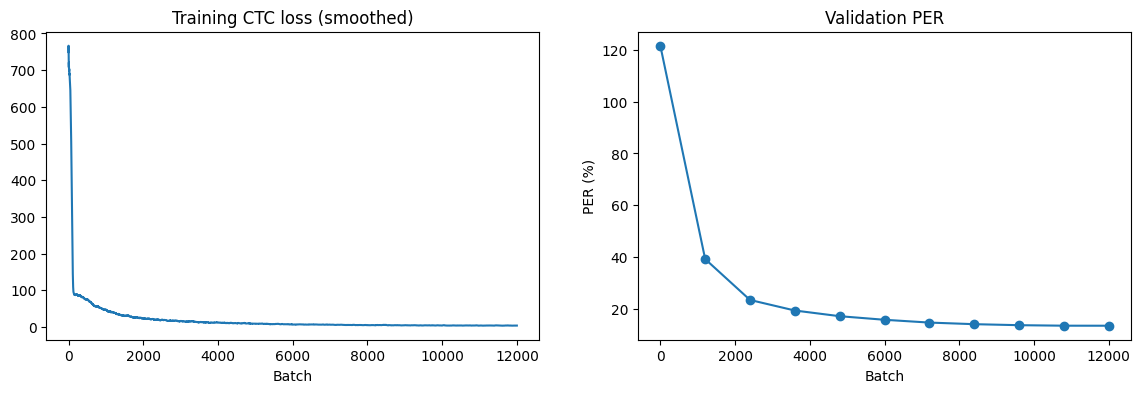

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(pd.Series(stats["train_losses"]).rolling(50, min_periods=1).mean())
ax[0].set_title("Training CTC loss (smoothed)"); ax[0].set_xlabel("Batch")

val_at = [i for i in range(N_BATCHES) if i % args.batches_per_val_step == 0] + [N_BATCHES - 1]
ax[1].plot(val_at[:len(stats["val_PERs"])], np.array(stats["val_PERs"]) * 100, marker="o")
ax[1].set_title("Validation PER"); ax[1].set_xlabel("Batch"); ax[1].set_ylabel("PER (%)")
plt.show()

training curves

In [5]:
BUDGET_HOURS = 5
sec_per_batch = elapsed / N_BATCHES      # includes compile and validation time, so it's a safe overestimate
n = int(BUDGET_HOURS * 3600 / sec_per_batch) // 1000 * 1000
print(f"{sec_per_batch:.2f} s/batch → about {n:,} batches fit in {BUDGET_HOURS} h")

1.03 s/batch → about 17,000 batches fit in 5 h


quick test: how many batches fit in budget